**Реализация алгоритма полиномиальной регрессии на Scikit-Learn**

Описание задания к работе.

1. Для выполнения используя  библиотека Scikit-Learn (https://scikit-learn.org)
2. Реализовать метод полиномиальной регрессии для заданного набора данных  используя различные степени полиномов (не менее 3х)
3. Отрисовать данные и регрессионные кривые на одном графике (использовать разные цвета с легендой).
4. Выбрать лучшую из полученных моделей используя метрики  MSE, R2, MAPE. 
5. Метрики для всех моделей собрать в таблицу
6. Сделать вывод по работе и обьяснить выбор степени полинома
* попробовать для данного набора данных применить линейную регрессию, нарисовать ее совместно с кривыми посчитать метрики

·	- звездочка означает необязательную часть работы


In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn import linear_model as lm
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error

In [28]:
data = pd.read_csv('lab2_2_DS.csv')
x_column = data.columns[0]
y_column = data.columns[1]

X = data[x_column].values.reshape(-1, 1)
Y = data[y_column].values

In [29]:
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

In [30]:
degrees = [1, 2, 3, 4]
X_grid = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)

train_preds = {}
test_preds = {}

for deg in degrees:
    poly = PolynomialFeatures(degree=deg)
    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)
    X_grid_poly = poly.transform(X_grid)
    
    model = lm.LinearRegression()
    model.fit(X_train_poly, y_train)

    train_preds[deg] = model.predict(X_grid_poly)
    test_preds[deg] = model.predict(X_test_poly)

colors = {1: 'red', 2: 'blue', 3: 'green', 4: 'darkorange'}
labels = {1: 'Линейная', 2: 'Полином ст. 2', 3: 'Полином ст. 3', 4: 'Полином ст. 4'}

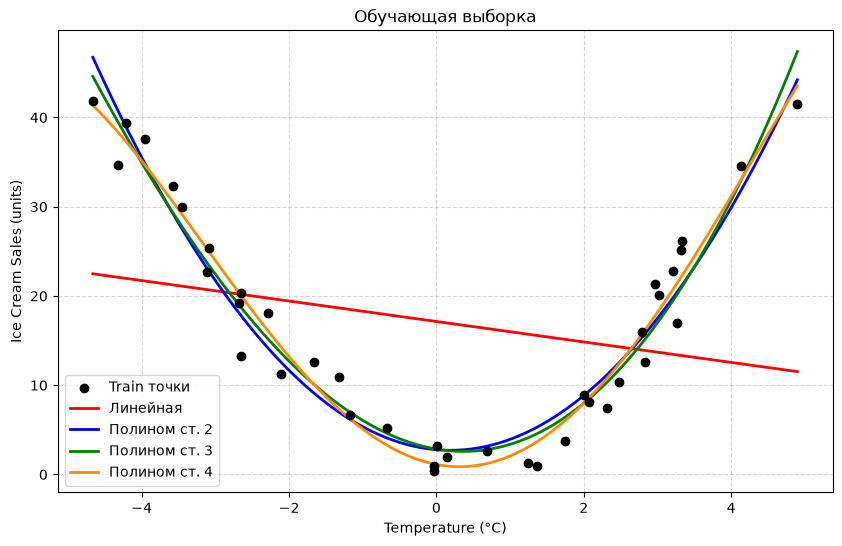

In [31]:
plt.figure(figsize=(10, 6))
plt.scatter(X_train, y_train, color='black', label='Train точки', zorder=5)

for deg in degrees:
    plt.plot(X_grid, train_preds[deg], color=colors[deg], linewidth=2, label=labels[deg])

plt.title("Обучающая выборка")
plt.xlabel(x_column)
plt.ylabel(y_column)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

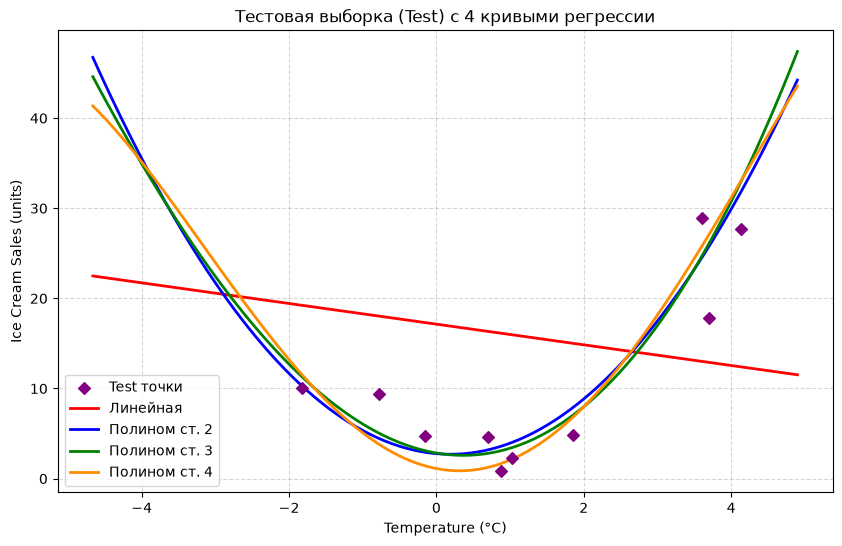

In [32]:
plt.figure(figsize=(10, 6))
plt.scatter(X_test, y_test, color='purple', marker='D', label='Test точки', zorder=5)

for deg in degrees:
    plt.plot(X_grid, train_preds[deg], color=colors[deg], linewidth=2, label=labels[deg])

plt.title("Тестовая выборка (Test) с 4 кривыми регрессии")
plt.xlabel(x_column)
plt.ylabel(y_column)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [33]:
metrics_list = []

for deg in degrees:
    name = labels[deg]
    y_pred = test_preds[deg]
    
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred)
    
    metrics_list.append({
        'Модель / Степень': name,
        'MSE': round(mse, 2),
        'R2': round(r2, 5),
        'MAPE': round(mape, 5),
        'MAPE (%)': round(mape * 100, 4)
    })

metrics_df = pd.DataFrame(metrics_list)
best_model = metrics_df.loc[metrics_df['R2'].idxmax(), 'Модель / Степень']
print(f"Лучшая модель по метрике R2: {best_model}\n")
metrics_df

Лучшая модель по метрике R2: Полином ст. 2



,Модель / Степень,MSE,R2,MAPE,MAPE (%)
0,Линейная,149.33,-0.57513,3.58737,358.7373
1,Полином ст. 2,14.88,0.84306,0.68725,68.7247
2,Полином ст. 3,15.12,0.84051,0.59596,59.5957
3,Полином ст. 4,18.44,0.80545,0.45739,45.7386


**Итог:** для данных с таким распределением линейной модели недостаточно, это видно по огромной среднеквадратичной ошибки и коэффициенту детерминации. Оптимальной является 2-я или 3-я степень полинома, они показали лучшие значения метрик. Дальнейшее увеличение степени на небольшом наборе данных избыточно и может привести к переобучению, т.к кривая начинает изгибаться на границах графика.